      exam 1     exam 2  admitted
0  34.623660  78.024693         0
1  30.286711  43.894998         0
2  35.847409  72.902198         0
3  60.182599  86.308552         1
4  79.032736  75.344376         1
5  45.083277  56.316372         0
6  61.106665  96.511426         1
7  75.024746  46.554014         1
8  76.098787  87.420570         1
9  84.432820  43.533393         1
           exam 1      exam 2    admitted
count  100.000000  100.000000  100.000000
mean    65.644274   66.221998    0.600000
std     19.458222   18.582783    0.492366
min     30.058822   30.603263    0.000000
25%     50.919511   48.179205    0.000000
50%     67.032988   67.682381    1.000000
75%     80.212529   79.360605    1.000000
max     99.827858   98.869436    1.000000


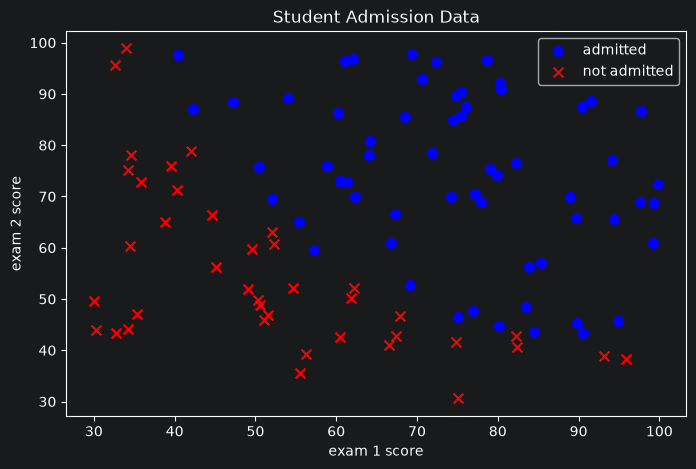

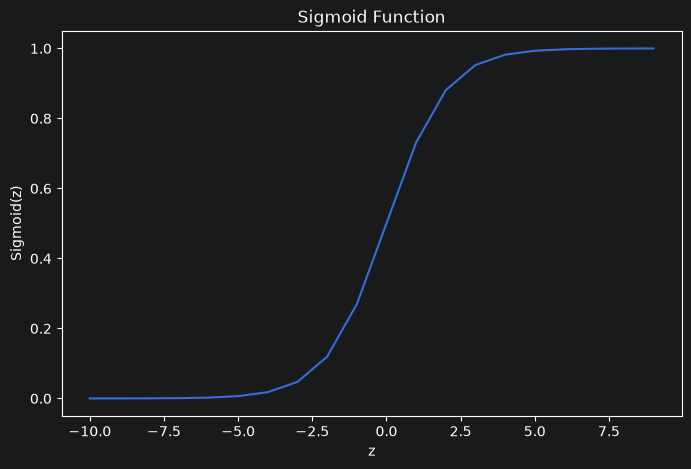

Initial Cost =  0.6931471805599453
Cost After Optimization =  0.20349770158947444
Accuracy = 89%


In [1]:
# 1. Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.optimize as opt


# 2. Load Dataset
path = r"C:\Users\(Victor)\Downloads\ex2data1.txt"

data = pd.read_csv(
    path,
    header=None,
    names=['exam 1', 'exam 2', 'admitted']
)

print(data.head(10))
print(data.describe())


# 3. Separate Positive and Negative Examples
positive = data[data['admitted'].isin([1])]
negative = data[data['admitted'].isin([0])]


# 4. Data Visualization
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    positive['exam 1'], positive['exam 2'],
    s=50, marker='o', color='blue', label='admitted'
)

ax.scatter(
    negative['exam 1'], negative['exam 2'],
    s=50, marker='x', color='red', label='not admitted'
)

ax.legend()
ax.set_xlabel('exam 1 score')
ax.set_ylabel('exam 2 score')
ax.set_title('Student Admission Data')

plt.show()


# 5. Sigmoid Function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))


nums = np.arange(-10, 10, step=1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(nums, sigmoid(nums))
ax.set_title('Sigmoid Function')
ax.set_xlabel('z')
ax.set_ylabel('Sigmoid(z)')

plt.show()


# 6. Cost Function
def cost(thetav, xv, yv):
    thetav = np.matrix(thetav)
    xv = np.matrix(xv)
    yv = np.matrix(yv)

    first = np.multiply(-yv, np.log(sigmoid(xv * thetav.T)))
    second = np.multiply((1-yv), np.log(1-sigmoid(xv * thetav.T)))

    return np.sum(first-second) / len(xv)


# 7. Prepare Data
data.insert(0, 'ones', 1)

cols = data.shape[1]

x = data.iloc[:, 0:cols-1]
y = data.iloc[:, cols-1:cols]

x = np.array(x.values)
y = np.array(y.values)

theta = np.zeros(3)


# 8. Initial Cost
thiscost = cost(theta, x, y)
print('Initial Cost = ', thiscost)


# 9. Gradient Function
def gradient(thetav, xv, yv):
    thetav = np.matrix(thetav)
    xv = np.matrix(xv)
    yv = np.matrix(yv)

    parameters = int(thetav.ravel().shape[1])
    grad = np.zeros(parameters)

    error = sigmoid(xv * thetav.T) - yv

    for i in range(parameters):
        term = np.multiply(error, xv[:, i])
        grad[i] = np.sum(term) / len(xv)

    return grad


# 10. Model Optimization
result = opt.fmin_tnc(
    func=cost,
    x0=theta,
    fprime=gradient,
    args=(x, y)
)


# 11. Cost After Optimization
costafteroptimize = cost(result[0], x, y)
print('Cost After Optimization = ', costafteroptimize)


# 12. Prediction Function
def predict(theta, x):
    probability = sigmoid(x * theta.T)

    return [
        1 if p >= 0.5 else 0
        for p in probability
    ]


theta_min = np.matrix(result[0])
predictions = predict(theta_min, x)


# 13. Model Accuracy
correct = [
    1 if a == b else 0
    for a, b in zip(predictions, y.flatten())
]

accuracy = sum(correct) % len(correct)

print('Accuracy = {0}%'.format(accuracy))